# CardioIA – Fase 3 · Ir Além 2
## Detecção de fibrilação atrial em séries de batimentos: regressão logística × rede neuromórfica LIF

**Objetivo.** Comparar um classificador tradicional (**regressão logística**) com uma **rede neuromórfica simples baseada no neurônio LIF** (*Leaky Integrate-and-Fire*) na tarefa de reconhecer **fibrilação atrial (FA)** a partir da série temporal de **intervalos RR**, isto é, o tempo entre um batimento e o seguinte.

**Por que FA e por que intervalos RR?**

- A FA é a arritmia sustentada mais comum e aumenta o risco de AVC. Muitas vezes ela é assintomática, por isso monitores vestíveis que a detectam têm valor clínico real.
- Na FA a frequência pode estar "normal" (por exemplo, 80 bpm), mas os batimentos ficam **irregulares**. Uma regra de limite, como o alerta de taquicardia > 120 bpm das Partes 1 e 2, não resolve: é preciso olhar o **padrão** da série.
- O wearable do CardioIA (Partes 1 e 2) já registra o **instante de cada batimento** (o botão de pulso). A sequência de intervalos entre esses instantes é exatamente a entrada destes modelos.

**Dados.** *MIT-BIH Atrial Fibrillation Database* (PhysioNet): 25 pacientes, cerca de 10 h de Holter cada, com os episódios de FA anotados por cardiologistas. Usamos apenas as anotações (instante de cada batimento e trechos de ritmo), não o sinal de ECG.

> Moody GB, Mark RG. *A new method for detecting atrial fibrillation using R-R intervals.* Computers in Cardiology 10:227-230 (1983). Goldberger AL et al. *PhysioBank, PhysioToolkit, and PhysioNet.* Circulation 101(23):e215-e220 (2000).

**Roteiro do notebook**

1. Carregamento e exploração dos dados
2. Janelamento da série de batimentos
3. Modelo 1: regressão logística com medidas de variabilidade
4. Modelo 2: rede LIF (codificador de eventos + neurônio LIF)
5. Avaliação com separação **por paciente**
6. Eficiência computacional
7. Demonstração em fluxo contínuo (como no wearable)
8. Efeito do tamanho da janela
9. Conclusões: vantagens e limitações

In [1]:
# Bibliotecas e configurações gerais
import os
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb  # leitura dos arquivos da PhysioNet

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (roc_auc_score, roc_curve, balanced_accuracy_score,
                             recall_score, f1_score)

PASTA_DADOS = 'dados/afdb'
PASTA_FIGURAS = 'figuras'
os.makedirs(PASTA_FIGURAS, exist_ok=True)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
COR_N, COR_FA = '#1e88e5', '#d32f2f'  # azul = ritmo normal, vermelho = FA

## 1. Carregamento e exploração dos dados

Para cada paciente baixamos três arquivos pequenos (cerca de 2,6 MB no total):

- `.qrs`: instante de cada batimento detectado (complexo QRS), em amostras a 250 Hz;
- `.atr`: trechos de ritmo anotados (`(N` normal, `(AFIB` fibrilação atrial, `(AFL` flutter atrial, `(J` ritmo juncional);
- `.hea`: cabeçalho do registro.

Se os arquivos já estiverem na pasta `dados/afdb`, o download é pulado.

In [2]:
# Baixa as anotações da PhysioNet apenas se ainda não existirem localmente
registros_locais = sorted({f.split('.')[0] for f in os.listdir(PASTA_DADOS)}) if os.path.isdir(PASTA_DADOS) else []
if len(registros_locais) < 25:
    registros = wfdb.get_record_list('afdb')
    os.makedirs(PASTA_DADOS, exist_ok=True)
    wfdb.dl_files('afdb', PASTA_DADOS, [f'{r}.{ext}' for r in registros for ext in ('atr', 'qrs', 'hea')])
REGISTROS = sorted({f.split('.')[0] for f in os.listdir(PASTA_DADOS)})
print(f'{len(REGISTROS)} pacientes:', ', '.join(REGISTROS))

25 pacientes: 00735, 03665, 04015, 04043, 04048, 04126, 04746, 04908, 04936, 05091, 05121, 05261, 06426, 06453, 06995, 07162, 07859, 07879, 07910, 08215, 08219, 08378, 08405, 08434, 08455


In [3]:
def carregar_registro(rec):
    # Devolve, para cada batimento i: instante t_i (s), intervalo RR_i = t_i - t_(i-1) (s)
    # e o ritmo anotado naquele instante.
    ritmos = wfdb.rdann(f'{PASTA_DADOS}/{rec}', 'atr')
    batidas = wfdb.rdann(f'{PASTA_DADOS}/{rec}', 'qrs')
    t = batidas.sample / batidas.fs
    # cada batimento herda o último rótulo de ritmo anotado antes dele
    idx = np.searchsorted(ritmos.sample, batidas.sample, side='right') - 1
    ritmo = np.array([ritmos.aux_note[i].strip() if i >= 0 else '' for i in idx])
    rr = np.diff(t)
    return t[1:], rr, ritmo[1:]

DADOS = {rec: carregar_registro(rec) for rec in REGISTROS}

# Horas de cada ritmo por paciente
linhas = []
for rec, (t, rr, ritmo) in DADOS.items():
    linha = {'paciente': rec, 'batimentos': len(rr)}
    for r in ['(N', '(AFIB', '(AFL', '(J']:
        linha[r] = rr[ritmo == r].sum() / 3600
    linhas.append(linha)
resumo = pd.DataFrame(linhas).set_index('paciente')
print('Total de horas por ritmo:')
print(resumo[['(N', '(AFIB', '(AFL', '(J']].sum().round(1).to_string())
resumo.round(2)

Total de horas por ritmo:
(N       149.1
(AFIB     93.3
(AFL       1.4
(J         5.2


,batimentos,(N,(AFIB,(AFL,(J
paciente,,,,,
00735,40232,9.93,0.07,0.00,0.00
03665,52764,3.24,1.65,0.00,5.10
04015,44004,9.93,0.07,0.00,0.00
04043,61914,7.80,2.19,0.00,0.00
04048,39933,9.66,0.10,0.00,0.00
04126,42859,9.62,0.38,0.00,0.00
04746,47872,4.57,5.43,0.00,0.00
04908,61759,9.07,0.86,0.07,0.00
04936,53645,1.91,7.37,0.71,0.00


Há cerca de 149 h de ritmo normal e 93 h de FA. Os ritmos `(AFL` e `(J` são raros (cerca de 7 h somados) e ficam fora do problema binário.

A distribuição por paciente é desigual: alguns quase só têm ritmo normal (00735, 05091) e outros só FA (07162, 07859). Isso reforça a necessidade de avaliar **por paciente** (seção 5).

A figura abaixo mostra **por que os intervalos RR bastam**. No mesmo paciente, o ritmo normal varia devagar. Na FA, cada intervalo é quase independente do anterior. No **gráfico de Poincaré** (RRᵢ × RRᵢ₊₁), o ritmo normal forma uma nuvem estreita na diagonal, e a FA espalha os pontos.

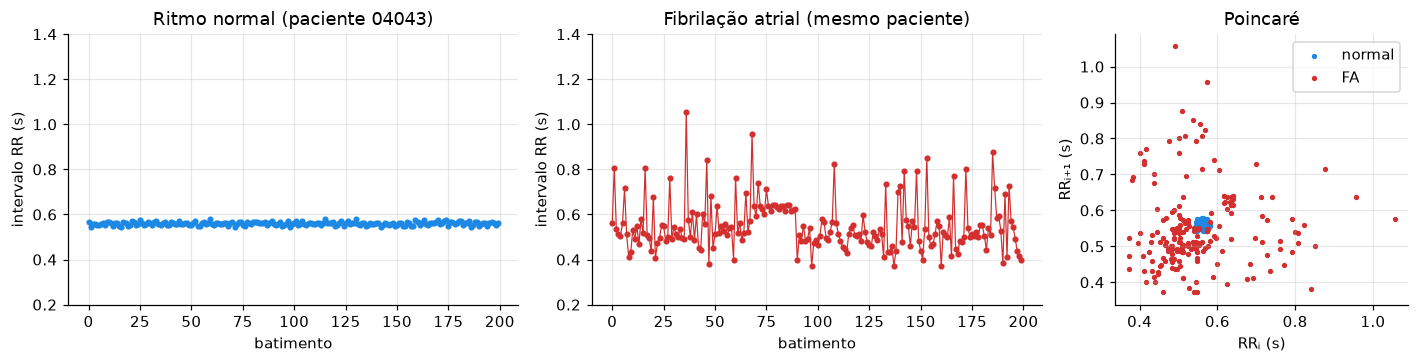

In [4]:
# Exemplo visual: 200 batimentos de ritmo normal e 200 de FA do mesmo paciente
t, rr, ritmo = DADOS['04043']
i_n = np.flatnonzero(ritmo == '(N')[5000]
i_fa = np.flatnonzero(ritmo == '(AFIB')[5000]
seg_n, seg_fa = rr[i_n:i_n + 200], rr[i_fa:i_fa + 200]

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), gridspec_kw={'width_ratios': [2, 2, 1.3]})
ax[0].plot(seg_n, '.-', color=COR_N, lw=0.8); ax[0].set_title('Ritmo normal (paciente 04043)')
ax[1].plot(seg_fa, '.-', color=COR_FA, lw=0.8); ax[1].set_title('Fibrilação atrial (mesmo paciente)')
for a in ax[:2]:
    a.set_xlabel('batimento'); a.set_ylabel('intervalo RR (s)'); a.set_ylim(0.2, 1.4)
ax[2].scatter(seg_n[:-1], seg_n[1:], s=6, color=COR_N, label='normal')
ax[2].scatter(seg_fa[:-1], seg_fa[1:], s=6, color=COR_FA, label='FA')
ax[2].set_xlabel('RRᵢ (s)'); ax[2].set_ylabel('RRᵢ₊₁ (s)'); ax[2].set_title('Poincaré'); ax[2].legend()
plt.tight_layout(); plt.savefig(f'{PASTA_FIGURAS}/fig1_rr_normal_vs_fa.png', bbox_inches='tight'); plt.show()

## 2. Janelamento da série de batimentos

Os dois modelos decidem sobre **janelas de 60 batimentos consecutivos** (cerca de 45 s), sem sobreposição. As regras são:

- **Rótulo:** FA (1) se os 60 batimentos estão num trecho `(AFIB`; normal (0) se todos estão em `(N`. Janelas mistas (transições), `(AFL` e `(J` são descartadas, para que o rótulo seja inequívoco.
- **Artefatos:** a janela é descartada se tiver algum RR < 0,25 s ou > 2,5 s (fora da faixa fisiológica, típico de batimento perdido ou detectado em dobro).
- Cada janela guarda também o RR **anterior** a ela, para que a primeira variação ΔRR possa ser calculada sem olhar o futuro.

Cada janela vem com o identificador do paciente (`grupos`), usado na separação treino/teste.

In [5]:
def gerar_janelas(n_batidas):
    X, y, grupos = [], [], []
    for rec, (t, rr, ritmo) in DADOS.items():
        for i in range(1, len(rr) - n_batidas + 1, n_batidas):
            janela = rr[i - 1:i + n_batidas]          # RR anterior + n_batidas RR da janela
            rotulos = ritmo[i:i + n_batidas]
            if (janela < 0.25).any() or (janela > 2.5).any():
                continue                              # artefato de detecção
            if (rotulos == '(AFIB').all():
                y.append(1)
            elif (rotulos == '(N').all():
                y.append(0)
            else:
                continue                              # janela mista, AFL ou J
            X.append(janela); grupos.append(rec)
    return np.array(X), np.array(y), np.array(grupos)

N_BATIDAS = 60
X, y, grupos = gerar_janelas(N_BATIDAS)
print(f'{len(y)} janelas de {N_BATIDAS} batimentos | FA: {y.sum()} ({y.mean():.0%}) | normal: {(y == 0).sum()}')

18593 janelas de 60 batimentos | FA: 8070 (43%) | normal: 10523


## 3. Modelo 1: regressão logística com medidas de variabilidade (HRV)

O modelo tradicional não enxerga a série batimento a batimento. Ele recebe **7 medidas resumo** de cada janela, clássicas na análise de variabilidade da frequência cardíaca:

| Medida | O que captura |
|---|---|
| RR médio | frequência média (60 / RR médio = bpm) |
| SDNN | desvio padrão dos RR: variabilidade global |
| RMSSD | raiz da média de ΔRR²: variação **batimento a batimento** |
| pNN50 | fração de \|ΔRR\| > 50 ms |
| CV | SDNN / RR médio (variabilidade relativa à frequência) |
| RMSSD normalizado | RMSSD / RR médio |
| Mediana \|ΔRR\| normalizada | variação típica, robusta a batimentos ectópicos isolados |

As medidas são padronizadas (`StandardScaler`) e a regressão usa `class_weight='balanced'`, para compensar a leve diferença entre o número de janelas normais e de FA.

In [6]:
NOMES_FEATURES = ['RR médio', 'SDNN', 'RMSSD', 'pNN50', 'CV', 'RMSSD norm.', 'Mediana |ΔRR| norm.']

def extrair_features(janelas):
    rr = janelas[:, 1:]                     # os RR da janela
    d = np.diff(janelas, axis=1)            # ΔRR (inclui a variação a partir do RR anterior)
    media = rr.mean(1)
    sdnn = rr.std(1)
    rmssd = np.sqrt((d ** 2).mean(1))
    pnn50 = (np.abs(d) > 0.05).mean(1)
    return np.c_[media, sdnn, rmssd, pnn50, sdnn / media, rmssd / media, np.median(np.abs(d), 1) / media]

def novo_modelo_logistico():
    return make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000))

F = extrair_features(X)
pd.DataFrame(F, columns=NOMES_FEATURES).groupby(y).median().rename(index={0: 'normal', 1: 'FA'}).round(3)

,RR médio,SDNN,RMSSD,pNN50,CV,RMSSD norm.,Mediana |ΔRR| norm.
normal,0.827,0.030,0.029,0.05,0.034,0.032,0.015
FA,0.620,0.137,0.188,0.75,0.213,0.294,0.184


A tabela de medianas já mostra a separação: na FA, as medidas de variação batimento a batimento (RMSSD, pNN50 e as normalizadas) ficam várias vezes maiores, enquanto o RR médio quase não muda. Isso confirma que a **frequência**, sozinha, não distingue FA.

Os coeficientes do modelo, com as medidas padronizadas, mostram quanto cada medida empurra a decisão para FA (positivo) ou para normal (negativo). O modelo abaixo é treinado com todos os dados **apenas para interpretação**; a avaliação está na seção 5.

In [7]:
# Coeficientes padronizados: quanto 1 desvio padrão a mais na medida altera o log-odds de FA
lr_todos = novo_modelo_logistico().fit(F, y)
coef = pd.Series(lr_todos[-1].coef_[0], index=NOMES_FEATURES).sort_values(key=np.abs, ascending=False)
coef.round(2).to_frame('coeficiente')

,coeficiente
RMSSD norm.,-5.34
pNN50,4.89
SDNN,4.67
RR médio,-4.05
Mediana |ΔRR| norm.,-0.40
RMSSD,0.39
CV,0.30


**Atenção ao ler esses coeficientes.** O *RMSSD normalizado* recebe peso **negativo**, embora seja muito maior na FA (tabela anterior). Não é erro: as medidas de variabilidade são fortemente correlacionadas entre si (multicolinearidade) e o modelo distribui o efeito entre elas com sinais trocados. Na prática, o conjunto "pNN50 + SDNN − RMSSD normalizado" representa a irregularidade. A interpretabilidade da regressão logística existe, mas exige cuidado quando as variáveis são redundantes.

## 4. Modelo 2: rede neuromórfica LIF

### O neurônio LIF

O *Leaky Integrate-and-Fire* é o modelo de neurônio mais simples usado em computação neuromórfica. O potencial de membrana $V$ **integra** a corrente de entrada, **vaza** com constante de tempo $\tau$ e **dispara** quando passa do limiar $\theta$:

$$\tau \frac{dV}{dt} = -V + \tau\, I(t), \qquad V \ge \theta \;\Rightarrow\; \text{spike},\; V \leftarrow 0$$

Como a entrada só chega nos batimentos, a equação tem **solução exata entre eventos**. Do batimento $i-1$ ao $i$, separados por $RR_i$ segundos, o potencial decai por $e^{-RR_i/\tau}$. Não é preciso integrar numericamente em passos fixos: o cálculo só acontece quando há batimento (processamento **orientado a eventos**, como num chip neuromórfico).

### A rede (duas camadas)

1. **Codificador de eventos (camada de entrada).** A cada batimento, calcula a variação relativa $x_i = |RR_i - RR_{i-1}| / RR_{i-1}$ e emite um *spike* se $x_i > \delta$. A série de batimentos vira um **trem de spikes de irregularidade**.
2. **Neurônio LIF integrador (camada de saída).** Recebe esses spikes com peso $w$:
   $V_i = V_{i-1}\, e^{-RR_i/\tau} + w\, s_i$. Se $V_i \ge \theta = 1$, dispara e volta a 0.

**Decisão:** a janela é classificada como FA se a **taxa de disparo** do neurônio de saída (spikes por batimento) passar de um limiar $r^*$.

Intuição: em ritmo normal, variações grandes são raras e isoladas, e o potencial vaza antes de acumular. Na FA, as irregularidades chegam em sequência, o potencial se acumula e o neurônio dispara com frequência.

### Calibração

A rede tem **4 parâmetros interpretáveis**: $\delta$ (quanto de variação conta como irregular), $\tau$ (memória em segundos), $w$ (peso sináptico) e $r^*$ (limiar de decisão). Não há gradiente: em cada rodada de validação, eles são escolhidos por **busca em grade nos dados de treino**, maximizando a acurácia balanceada.

In [8]:
def rede_lif(janelas, delta, tau, w, tracos=False):
    rr = janelas[:, 1:]
    variacao = np.abs(np.diff(janelas, axis=1)) / janelas[:, :-1]   # |ΔRR| relativo (causal)
    spikes_entrada = variacao > delta                                # camada 1: codificador de eventos
    V = np.zeros(len(janelas))
    spikes_saida = np.zeros_like(variacao, dtype=bool)
    hist_V = np.zeros_like(variacao)
    for i in range(variacao.shape[1]):                               # um passo por batimento
        V = V * np.exp(-rr[:, i] / tau) + w * spikes_entrada[:, i]   # vazamento exato + integração
        disparou = V >= 1.0                                          # limiar θ = 1
        spikes_saida[:, i] = disparou
        hist_V[:, i] = V
        V[disparou] = 0.0                                            # reset após o spike
    taxa = spikes_saida.mean(1)                                      # spikes por batimento
    if tracos:
        return taxa, spikes_entrada, hist_V, spikes_saida
    return taxa

GRADE_LIF = {'delta': [0.01, 0.02, 0.03, 0.05, 0.08, 0.12],
             'tau':   [1, 2, 4, 8, 16],
             'w':     [0.25, 0.5, 1.0]}

def calibrar_lif(Xtr, ytr):
    melhor = None
    for delta, tau, w in itertools.product(*GRADE_LIF.values()):
        taxa = rede_lif(Xtr, delta, tau, w)
        for limiar in np.unique(np.quantile(taxa, np.linspace(0.02, 0.98, 49))):
            ba = balanced_accuracy_score(ytr, taxa >= limiar)
            if melhor is None or ba > melhor['acc_bal_treino']:
                melhor = {'delta': delta, 'tau': tau, 'w': w, 'limiar': limiar, 'acc_bal_treino': ba}
    return melhor

Para visualizar o funcionamento, calibramos a rede com todas as janelas (**apenas para ilustração**; a avaliação honesta está na seção 5) e olhamos uma janela normal e uma de FA.

Parâmetros (ilustração): {'delta': 0.03, 'tau': 8.0, 'w': 0.25, 'limiar': 0.133, 'acc_bal_treino': 0.961}


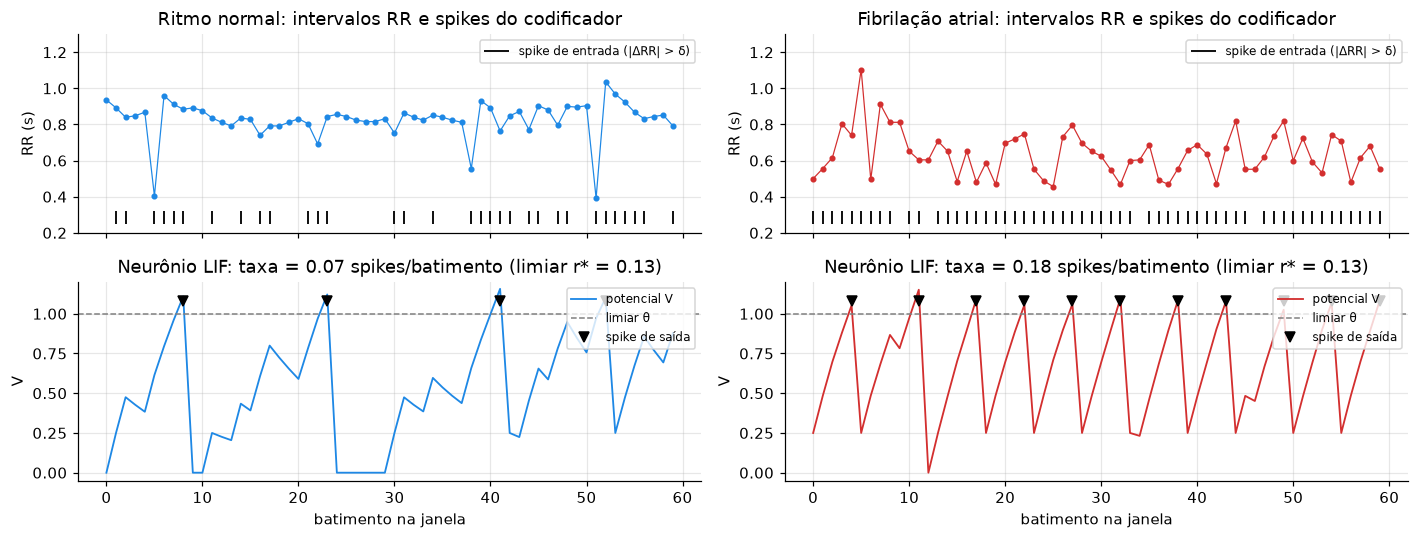

In [9]:
P_ILUSTRA = calibrar_lif(X, y)
print('Parâmetros (ilustração):', {k: round(float(v), 3) for k, v in P_ILUSTRA.items()})

ex_n = X[np.flatnonzero(y == 0)[3000]][None, :]
ex_fa = X[np.flatnonzero(y == 1)[3000]][None, :]
fig, ax = plt.subplots(2, 2, figsize=(13, 5), sharex=True)
for col, (ex, nome, cor) in enumerate([(ex_n, 'Ritmo normal', COR_N), (ex_fa, 'Fibrilação atrial', COR_FA)]):
    taxa, s_in, hist_V, s_out = rede_lif(ex, P_ILUSTRA['delta'], P_ILUSTRA['tau'], P_ILUSTRA['w'], tracos=True)
    k = np.arange(s_in.shape[1])
    ax[0, col].plot(k, ex[0, 1:], '.-', color=cor, lw=0.8)
    ax[0, col].vlines(k[s_in[0]], 0.25, 0.32, color='k', lw=1.2, label='spike de entrada (|ΔRR| > δ)')
    ax[0, col].set_title(f'{nome}: intervalos RR e spikes do codificador'); ax[0, col].set_ylabel('RR (s)')
    ax[0, col].set_ylim(0.2, 1.3); ax[0, col].legend(loc='upper right', fontsize=8)
    ax[1, col].plot(k, hist_V[0], color=cor, lw=1.2, label='potencial V')
    ax[1, col].axhline(1.0, ls='--', color='gray', lw=1, label='limiar θ')
    ax[1, col].plot(k[s_out[0]], np.full(s_out[0].sum(), 1.08), 'v', color='k', ms=6, label='spike de saída')
    ax[1, col].set_title(f'Neurônio LIF: taxa = {taxa[0]:.2f} spikes/batimento (limiar r* = {P_ILUSTRA["limiar"]:.2f})')
    ax[1, col].set_xlabel('batimento na janela'); ax[1, col].set_ylabel('V'); ax[1, col].set_ylim(-0.05, 1.2)
    ax[1, col].legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.savefig(f'{PASTA_FIGURAS}/fig2_lif_funcionamento.png', bbox_inches='tight'); plt.show()

## 5. Avaliação com separação por paciente

**Cuidado metodológico central.** Janelas do mesmo paciente são muito parecidas entre si. Se forem sorteadas aleatoriamente entre treino e teste, o modelo "reconhece o paciente" e o resultado sai inflado. Por isso usamos **validação cruzada agrupada por paciente** (`GroupKFold`, 5 rodadas): em cada rodada, cerca de 5 pacientes ficam inteiramente de fora do treino e só são vistos no teste. É o cenário real de um wearable usado por alguém novo.

Os dois modelos passam exatamente pelas mesmas rodadas. Toda calibração, inclusive a grade do LIF e o limiar $r^*$, usa apenas o treino da rodada.

**Métricas** (FA = classe positiva):

- **AUC**: capacidade de ordenar FA acima de normal, independente do limiar;
- **acurácia balanceada**: média de sensibilidade e especificidade;
- **sensibilidade**: fração das janelas de FA detectadas (o que mais importa clinicamente);
- **especificidade**: fração das janelas normais corretamente não alarmadas (evita alarmes falsos);
- **F1**: equilíbrio entre precisão e sensibilidade.

In [10]:
def metricas(y_true, escore, previsto):
    return {'AUC': roc_auc_score(y_true, escore),
            'Acurácia balanceada': balanced_accuracy_score(y_true, previsto),
            'Sensibilidade': recall_score(y_true, previsto),
            'Especificidade': recall_score(y_true, previsto, pos_label=0),
            'F1': f1_score(y_true, previsto)}

def avaliar(X, y, grupos, verbose=True):
    F = extrair_features(X)
    oof = {'LR': np.zeros(len(y)), 'LIF': np.zeros(len(y))}       # escores fora da rodada (out-of-fold)
    pred = {'LR': np.zeros(len(y), bool), 'LIF': np.zeros(len(y), bool)}
    linhas, params = [], []
    for k, (tr, te) in enumerate(GroupKFold(n_splits=5).split(X, y, grupos)):
        lr = novo_modelo_logistico().fit(F[tr], y[tr])
        p = lr.predict_proba(F[te])[:, 1]
        oof['LR'][te], pred['LR'][te] = p, p >= 0.5
        linhas.append({'rodada': k, 'modelo': 'Regressão logística', **metricas(y[te], p, p >= 0.5)})

        P = calibrar_lif(X[tr], y[tr])
        taxa = rede_lif(X[te], P['delta'], P['tau'], P['w'])
        oof['LIF'][te], pred['LIF'][te] = taxa, taxa >= P['limiar']
        linhas.append({'rodada': k, 'modelo': 'Rede LIF', **metricas(y[te], taxa, taxa >= P['limiar'])})
        params.append({'rodada': k, 'pacientes de teste': ', '.join(sorted(set(grupos[te]))), **P})
        if verbose:
            print(f'rodada {k}: LR AUC {linhas[-2]["AUC"]:.3f} | LIF AUC {linhas[-1]["AUC"]:.3f} | teste: {params[-1]["pacientes de teste"]}')
    return pd.DataFrame(linhas), pd.DataFrame(params), oof, pred

res, params_lif, oof, pred = avaliar(X, y, grupos)

rodada 0: LR AUC 0.992 | LIF AUC 0.993 | teste: 03665, 04746, 04908, 05121, 07162
rodada 1: LR AUC 0.973 | LIF AUC 0.983 | teste: 04015, 06426, 07859, 07910, 08378
rodada 2: LR AUC 0.996 | LIF AUC 0.989 | teste: 04043, 04048, 04126, 04936, 08455
rodada 3: LR AUC 0.991 | LIF AUC 0.977 | teste: 05091, 05261, 07879, 08405, 08434
rodada 4: LR AUC 0.923 | LIF AUC 0.952 | teste: 00735, 06453, 06995, 08215, 08219


In [11]:
# Média ± desvio padrão entre as 5 rodadas (cada rodada = pacientes nunca vistos)
tabela = res.drop(columns='rodada').groupby('modelo').agg(['mean', 'std'])
resumo_metricas = pd.DataFrame({m: [f'{tabela.loc[mod, (m, "mean")]:.3f} ± {tabela.loc[mod, (m, "std")]:.3f}' for mod in tabela.index]
                                for m in ['AUC', 'Acurácia balanceada', 'Sensibilidade', 'Especificidade', 'F1']},
                               index=tabela.index)
resumo_metricas

,AUC,Acurácia balanceada,Sensibilidade,Especificidade,F1
modelo,,,,,
Rede LIF,0.979 ± 0.016,0.959 ± 0.024,0.973 ± 0.028,0.945 ± 0.054,0.944 ± 0.050
Regressão logística,0.975 ± 0.031,0.951 ± 0.040,0.974 ± 0.017,0.927 ± 0.089,0.932 ± 0.075


In [12]:
# Parâmetros escolhidos para a rede LIF em cada rodada (estabilidade da calibração)
params_lif.assign(**{c: params_lif[c].astype(float).round(3) for c in ['limiar', 'acc_bal_treino']})

,rodada,pacientes de teste,delta,tau,w,limiar,acc_bal_treino
0,0,"03665, 04746, 04908, 05121, 07162",0.03,8,0.25,0.133,0.958
1,1,"04015, 06426, 07859, 07910, 08378",0.03,4,0.50,0.250,0.957
2,2,"04043, 04048, 04126, 04936, 08455",0.03,4,0.50,0.250,0.961
3,3,"05091, 05261, 07879, 08405, 08434",0.03,4,0.50,0.250,0.958
4,4,"00735, 06453, 06995, 08215, 08219",0.03,8,0.25,0.133,0.975


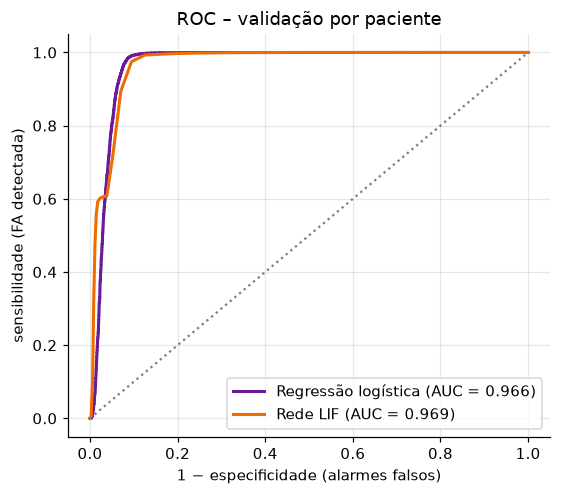

In [13]:
# Curvas ROC com os escores fora da rodada de todos os pacientes
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for nome, cor in [('LR', '#6a1b9a'), ('LIF', '#ef6c00')]:
    fpr, tpr, _ = roc_curve(y, oof[nome])
    rotulo = 'Regressão logística' if nome == 'LR' else 'Rede LIF'
    ax.plot(fpr, tpr, color=cor, lw=2, label=f'{rotulo} (AUC = {roc_auc_score(y, oof[nome]):.3f})')
ax.plot([0, 1], [0, 1], ls=':', color='gray')
ax.set_xlabel('1 − especificidade (alarmes falsos)'); ax.set_ylabel('sensibilidade (FA detectada)')
ax.set_title('ROC – validação por paciente'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(f'{PASTA_FIGURAS}/fig3_roc.png', bbox_inches='tight'); plt.show()

### Onde os modelos erram? Análise por paciente

A média esconde a variação entre pessoas, então olhamos o erro de cada paciente quando ele estava no conjunto de teste.

In [14]:
por_paciente = (pd.DataFrame({'paciente': grupos, 'y': y, 'LR': pred['LR'], 'LIF': pred['LIF']})
                .assign(erro_LR=lambda d: d.LR != d.y, erro_LIF=lambda d: d.LIF != d.y)
                .groupby('paciente')
                .agg(janelas=('y', 'size'), fracao_FA=('y', 'mean'), erro_LR=('erro_LR', 'mean'), erro_LIF=('erro_LIF', 'mean'))
                .sort_values('erro_LR', ascending=False))
por_paciente.round(3).head(8)

,janelas,fracao_FA,erro_LR,erro_LIF
paciente,,,,
08219,884,0.222,0.481,0.314
06995,898,0.491,0.174,0.112
04936,717,0.865,0.084,0.148
04015,678,0.007,0.077,0.065
07859,950,1.000,0.072,0.019
05261,704,0.013,0.054,0.036
04908,995,0.088,0.053,0.026
08434,653,0.052,0.044,0.054


## 6. Eficiência computacional

Num wearable, acertar não basta: o modelo precisa caber num microcontrolador e gastar pouca bateria. A comparação abaixo conta operações e memória **por batimento** na hora de usar o modelo (inferência), para janelas de 60 batimentos.

In [15]:
# Esparsidade: quantos eventos (spikes de entrada) a rede processa por janela
P = P_ILUSTRA
_, s_in, _, s_out = rede_lif(X, P['delta'], P['tau'], P['w'], tracos=True)
esparsidade = pd.DataFrame({'spikes de entrada por janela': [s_in[y == 0].sum(1).mean(), s_in[y == 1].sum(1).mean()],
                            'spikes de saída por janela': [s_out[y == 0].sum(1).mean(), s_out[y == 1].sum(1).mean()]},
                           index=['normal', 'FA']).round(1)
esparsidade

,spikes de entrada por janela,spikes de saída por janela
normal,15.5,1.8
FA,53.4,10.0


| | Regressão logística | Rede LIF |
|---|---|---|
| Memória de estado | buffer com os 60 últimos RR (240 bytes em float32) | 3 variáveis: V, RR anterior, contador de spikes (12 bytes) |
| Parâmetros | 7 pesos + 1 viés + 14 de padronização = 22 | 4 (δ, τ, w, r*) |
| Custo de inferência | ≈ 800 operações por janela (≈ 13 por batimento): médias, desvios, diferenças, ordenação para a mediana e 7 multiplicações | ≈ 6 operações por batimento (≈ 360 por janela): subtração, divisão, comparação, decaimento, soma só se houver spike e comparação |
| Natureza | precisa da janela completa para decidir | contínua: o estado é atualizado a cada batimento e a decisão pode sair a qualquer momento |
| Operação | aritmética densa em ponto flutuante | orientada a eventos: a soma sináptica só acontece quando há spike |

O decaimento $e^{-RR/\tau}$ pode ser trocado por uma tabela de consulta ou por uma multiplicação fixa por batimento, o que deixa a rede LIF implementável até em aritmética inteira. Isso caberia com folga no mesmo ESP32 das Partes 1 e 2, ou num chip neuromórfico como o Intel Loihi.

> Observação: medir tempo em Python não seria justo aqui, porque a regressão usa bibliotecas vetorizadas em C e a rede LIF foi escrita como laço explícito para ficar didática. A contagem de operações e de memória é a comparação que vale para o hardware embarcado.

## 7. Demonstração em fluxo contínuo (como no wearable)

Na prática, o dispositivo não recebe janelas recortadas: os batimentos chegam um a um, inclusive durante **transições** entre ritmo normal e FA, que foram excluídas da avaliação. Aqui a rede LIF roda **sem reiniciar** sobre um trecho contínuo de um paciente, e a regressão logística é aplicada a cada 5 batimentos sobre os 60 últimos RR.

Para ser honesto, os dois modelos são treinados **sem** o paciente mostrado. Os escores aparecem divididos pelo próprio limiar de cada modelo: **acima de 1 = alarme de FA**.

Mostramos dois pacientes: um caso típico (04043) e o caso mais difícil da base (08219).

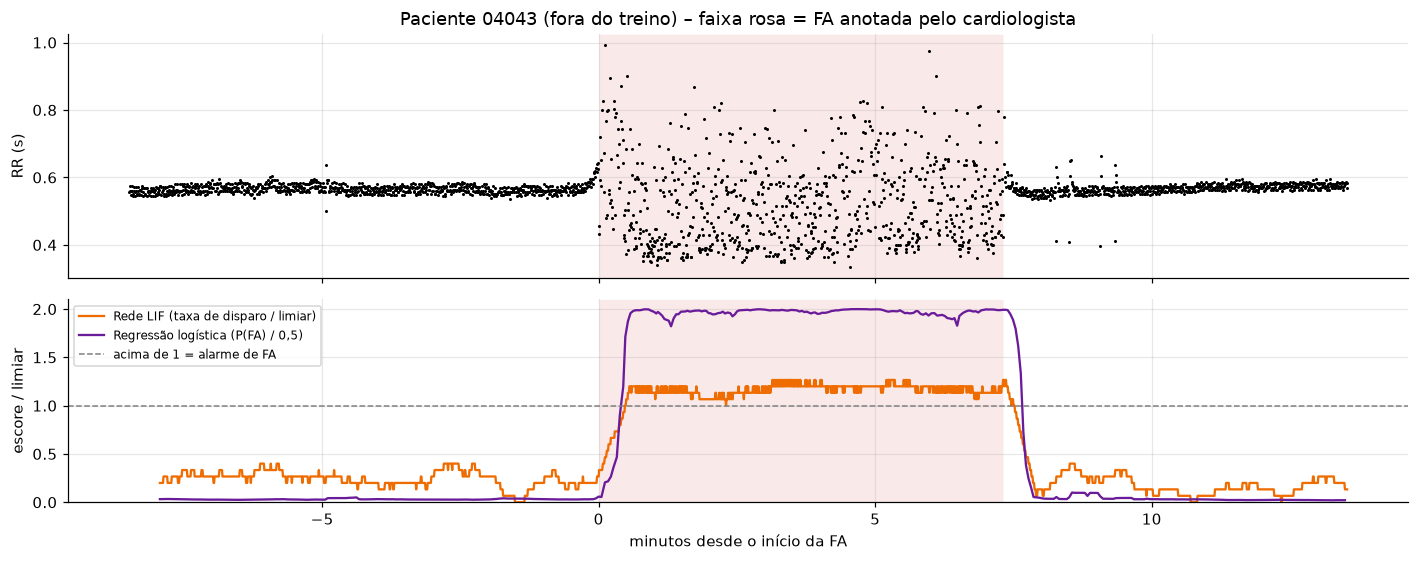

LIF: alarme 29 s após o início da FA | alarme falso antes da FA em 0% do tempo
Regressão logística: alarme 27 s após o início da FA | alarme falso antes da FA em 0% do tempo


In [16]:
def demo_fluxo(rec, arquivo, antes=900, depois=1500):
    # Treina os dois modelos sem o paciente 'rec' e os aplica ao trecho contínuo
    # em torno da primeira entrada em FA desse paciente.
    treino = grupos != rec
    lr = novo_modelo_logistico().fit(extrair_features(X[treino]), y[treino])
    P = calibrar_lif(X[treino], y[treino])

    t, rr, ritmo = DADOS[rec]
    inicio_fa = np.flatnonzero((ritmo[1:] == '(AFIB') & (ritmo[:-1] != '(AFIB'))[0] + 1
    ini, fim = max(inicio_fa - antes, N_BATIDAS + 1), inicio_fa + depois
    rr_seg, rit_seg = rr[ini - 1:fim], ritmo[ini:fim]
    t_seg = (t[ini:fim] - t[inicio_fa]) / 60                          # minutos (0 = início da FA)

    # Rede LIF em fluxo contínuo: um único neurônio, sem reinício entre janelas
    _, _, _, s_out = rede_lif(rr_seg[None, :], P['delta'], P['tau'], P['w'], tracos=True)
    taxa_movel = np.convolve(s_out[0], np.ones(N_BATIDAS) / N_BATIDAS, mode='full')[:len(rit_seg)]
    taxa_movel[:N_BATIDAS] = np.nan                                  # janela ainda incompleta
    escore_lif = taxa_movel / P['limiar']

    # Regressão logística a cada 5 batimentos sobre os 60 RR mais recentes
    pos = np.arange(N_BATIDAS, len(rit_seg), 5)
    prob = lr.predict_proba(extrair_features(np.array([rr_seg[p - N_BATIDAS:p + 1] for p in pos])))[:, 1]
    escore_lr = prob / 0.5

    em_fa = rit_seg == '(AFIB'
    fig, ax = plt.subplots(2, 1, figsize=(13, 5.2), sharex=True, gridspec_kw={'height_ratios': [1.2, 1]})
    for a in ax:
        a.fill_between(t_seg, 0, 1, where=em_fa, transform=a.get_xaxis_transform(), color=COR_FA, alpha=0.1, lw=0)
    ax[0].plot(t_seg, rr_seg[1:], '.', ms=2, color='k'); ax[0].set_ylabel('RR (s)')
    ax[0].set_title(f'Paciente {rec} (fora do treino) – faixa rosa = FA anotada pelo cardiologista')
    ax[1].plot(t_seg, escore_lif, color='#ef6c00', lw=1.5, label='Rede LIF (taxa de disparo / limiar)')
    ax[1].plot(t_seg[pos], escore_lr, color='#6a1b9a', lw=1.5, label='Regressão logística (P(FA) / 0,5)')
    ax[1].axhline(1, ls='--', color='gray', lw=1, label='acima de 1 = alarme de FA')
    ax[1].set_ylim(0, 2.1); ax[1].set_ylabel('escore / limiar'); ax[1].set_xlabel('minutos desde o início da FA')
    ax[1].legend(loc='upper left', fontsize=8)
    plt.tight_layout(); plt.savefig(f'{PASTA_FIGURAS}/{arquivo}', bbox_inches='tight'); plt.show()

    # Atraso até o alarme: só faz sentido se o modelo NÃO estava em alarme antes da FA
    i0 = np.argmax(em_fa)
    for nome, esc, tt in [('LIF', escore_lif, t_seg), ('Regressão logística', escore_lr, t_seg[pos])]:
        antes_fa, durante = esc[tt < 0], esc[tt >= 0]
        alarme_falso = np.nanmean(antes_fa >= 1)
        if np.isnan(antes_fa[-1]) or antes_fa[-1] < 1:
            atraso = tt[tt >= 0][np.argmax(durante >= 1)] * 60
            print(f'{nome}: alarme {atraso:.0f} s após o início da FA | alarme falso antes da FA em {alarme_falso:.0%} do tempo')
        else:
            print(f'{nome}: já estava em alarme antes da FA (alarme falso em {alarme_falso:.0%} do tempo antes da FA)')

demo_fluxo('04043', 'fig4_fluxo_continuo.png')

**Caso difícil: paciente 08219.** É o paciente com mais erros na avaliação por paciente (seção 5). No trecho "normal", os intervalos alternam entre cerca de 0,35 s e 0,65 s. Isso é **bigeminismo**: uma extrassístole a cada batimento normal. A série fica irregular sem ser FA, e os dois modelos, que só enxergam o ritmo, disparam alarmes falsos.

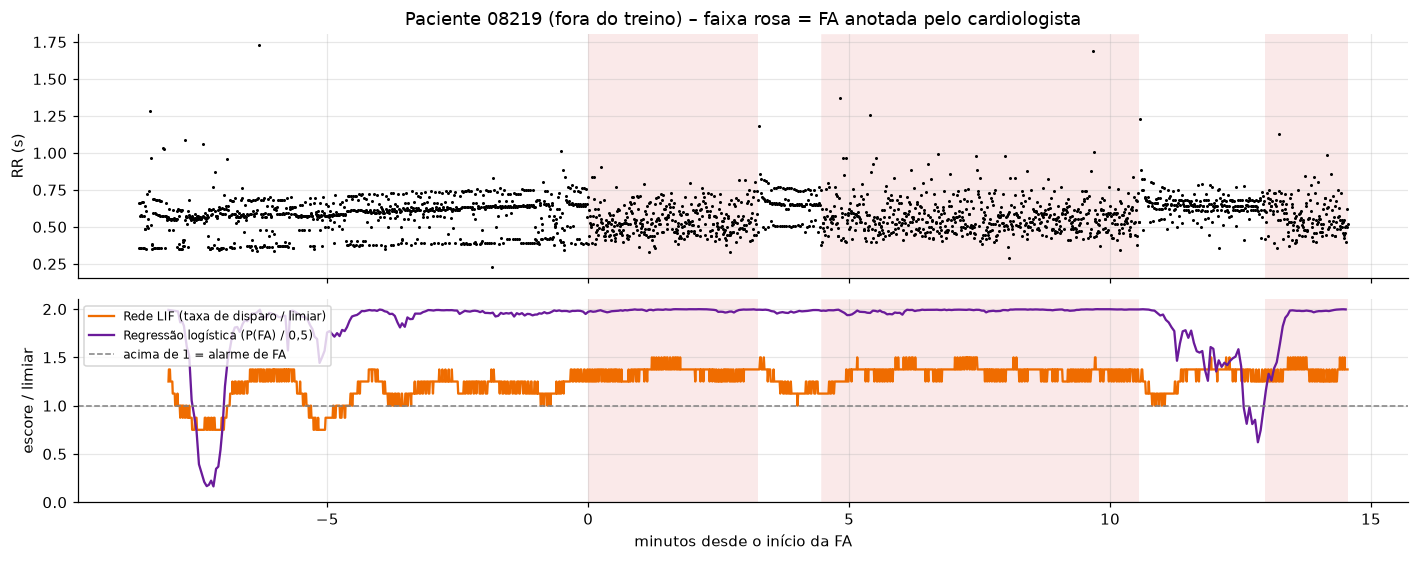

LIF: já estava em alarme antes da FA (alarme falso em 77% do tempo antes da FA)
Regressão logística: já estava em alarme antes da FA (alarme falso em 92% do tempo antes da FA)


In [17]:
demo_fluxo('08219', 'fig6_caso_dificil_bigeminismo.png')

## 8. Efeito do tamanho da janela

Janelas maiores dão mais evidência, mas atrasam o alarme. Repetimos a avaliação completa por paciente com 30, 60 e 120 batimentos (cerca de 22 s, 45 s e 90 s).

In [ ]:
linhas = []
for n in [30, 60, 120]:
    Xn, yn, gn = gerar_janelas(n)
    rn, _, _, _ = avaliar(Xn, yn, gn, verbose=False)
    for modelo, d in rn.groupby('modelo'):
        linhas.append({'batimentos por janela': n, 'modelo': modelo, 'janelas': len(yn),
                       'AUC': d['AUC'].mean(), 'Acurácia balanceada': d['Acurácia balanceada'].mean(),
                       'Sensibilidade': d['Sensibilidade'].mean(), 'Especificidade': d['Especificidade'].mean()})
efeito_janela = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(6, 3.6))
for modelo, cor in [('Regressão logística', '#6a1b9a'), ('Rede LIF', '#ef6c00')]:
    d = efeito_janela[efeito_janela.modelo == modelo]
    ax.plot(d['batimentos por janela'], d['Acurácia balanceada'], 'o-', color=cor, lw=2, label=modelo)
ax.set_xticks([30, 60, 120]); ax.set_xlabel('batimentos por janela'); ax.set_ylabel('acurácia balanceada')
ax.set_title('Mais batimentos = mais acerto, porém mais atraso'); ax.legend()
plt.tight_layout(); plt.savefig(f'{PASTA_FIGURAS}/fig5_tamanho_janela.png', bbox_inches='tight'); plt.show()
efeito_janela.round(3)

## 9. Conclusões: vantagens e limitações

### Resultado principal

Na validação por paciente (5 rodadas, pacientes de teste nunca vistos no treino), os dois modelos tiveram **desempenho praticamente igual**:

| Modelo | AUC | Acurácia balanceada | Sensibilidade | Especificidade |
|---|---|---|---|---|
| Regressão logística (7 medidas HRV) | 0,975 ± 0,031 | 0,951 ± 0,040 | 0,974 ± 0,017 | 0,927 ± 0,089 |
| Rede LIF (codificador + 1 neurônio) | 0,979 ± 0,016 | 0,959 ± 0,024 | 0,973 ± 0,028 | 0,945 ± 0,054 |

As diferenças de médias (≤ 0,02) são menores que a variação entre rodadas, então **não dá para afirmar que um seja melhor** com 25 pacientes. O que se pode afirmar é que uma rede neuromórfica com **4 parâmetros e 3 variáveis de estado** alcança o mesmo patamar de um classificador tradicional com engenharia de atributos. A rede LIF também foi **mais estável entre rodadas** (desvio padrão menor) e teve menos alarmes falsos em média. O ganho de janelas maiores é pequeno para os dois (seção 8), o que permite decidir com cerca de 45 s de dados.

### Rede LIF: vantagens

- **Fluxo contínuo e causal:** processa batimento a batimento com 12 bytes de estado, sem guardar janela nem calcular estatísticas. Encaixa direto no firmware do ESP32 das Partes 1 e 2, que já registra o instante de cada batimento.
- **Orientada a eventos e esparsa:** em ritmo normal, só cerca de 15 de cada 60 batimentos geram spike de entrada, e o neurônio de saída dispara menos de 2 vezes. A computação, e no hardware neuromórfico o consumo, acompanha a atividade.
- **Parâmetros com significado físico:** δ ≈ 3% de variação entre batimentos, τ de 4 a 8 s de memória. A calibração foi estável: δ = 0,03 em todas as rodadas, e as combinações (τ, w) escolhidas são equivalentes (2 a 4 irregularidades recentes disparam o neurônio).

### Rede LIF: limitações

- **Sem treino por gradiente:** a busca em grade funciona para 4 parâmetros, mas não escala. Redes maiores exigiriam *surrogate gradients* (por exemplo, com snnTorch).
- **Margem de decisão estreita:** em FA, a taxa de disparo fica só cerca de 10–20% acima do limiar (figura 4), contra probabilidade próxima de 1 na regressão. Um limiar mal ajustado degrada rápido.
- **Enxerga um único aspecto**, a irregularidade sucessiva, e é discreta (passos de 1/60 na taxa).

### Regressão logística: vantagens e limitações

- **Vantagens:** treino rápido e padrão, saída probabilística e fácil de incluir novas medidas. Teve sensibilidade ligeiramente maior com janelas de 120 batimentos.
- **Limitações:** depende de engenharia de atributos feita por especialista e de um buffer com a janela inteira. Os coeficientes enganam quando as medidas são redundantes (seção 3). Foi a menos estável entre rodadas: especificidade de 0,927 ± 0,089.

### Limitações comuns e próximos passos

- **Extrassístoles imitam FA.** No paciente 08219 (bigeminismo), os dois modelos ficaram em alarme falso durante quase todo o ritmo normal (77% do tempo no LIF, 92% na regressão). Só com intervalos RR não há como separar os dois casos; a solução clínica é olhar a onda P do ECG ou adicionar um detector de padrões alternados.
- **Base pequena e antiga:** 25 pacientes, Holter de 1983. As transições e o flutter atrial ficaram de fora da avaliação por janelas. O próximo passo seria validar em bases maiores (*Long-Term AF Database*, PhysioNet/CinC 2017) e com pulso óptico (PPG), que é o sensor real de relógios.
- **Integração com o CardioIA:** portar a rede LIF para o `sketch.ino`, alimentada pelos instantes de batimento já registrados pela interrupção do botão, e publicar o escore de FA no mesmo tópico MQTT da Parte 2. Assim o alerta de arritmia nasceria na borda, como os alertas de febre e taquicardia.